In [1]:
# Import the libraries you need for this project
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import randint, uniform, loguniform

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, VotingRegressor, StackingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

In [ ]:
# loading the dataset
df = pd.read_csv('data/bike_sharing.csv')

# converting the 'datetime' column to datetime type
df['datetime'] = pd.to_datetime(df['datetime'])

print(f"Dataset shape: {df.shape}")
print(df.dtypes)
df.head()

**Check:** October 2024 to September 2026 is 730 days (no 29 February in 2025 or 2026), and 730 × 24 hours = **17,520 rows**, which matches the shape. There is one row per hour, with no gaps, and the 13 columns match the data description.

## Step 1: Split into training and test set

- **Random split:** the model describes *typical* hours under given conditions; it does not forecast future dates (see the business problem). So the test hours can be drawn at random from the whole period. For a forecast, the test set would have to be the most recent hours instead.
- **The whole DataFrame is split**, so the features and `rentals` stay together. `X` and `y` are separated later.
- `test_size=0.2`: 20 % (≈ 3,500 hours) for the final test, 80 % for training.
- `random_state=42`: the same split every time the notebook runs.

From here on, everything is done on `df_train` only. `df_test` stays locked until step 8.

In [3]:
# splitting train and test data
df_train, df_test = train_test_split(df, test_size=0.2, random_state=42)

print(f"train: {df_train.shape}")
print(f"test:  {df_test.shape}")

train: (14016, 13)
test:  (3504, 13)


## Step 2 – Explore the training set

### 2a. Data quality

Checks for missing values, duplicates and impossible values are done **after** the split, on the training set only. Every decision that learns something from the data (how to fill missing values, which outliers to remove, …) must not be influenced by the test set, otherwise the test score looks better than it really is (leakage).

**Missing values**

In [4]:
df_train.isna().sum()

datetime             0
casual               0
member               0
rentals              0
temperature          0
feels_like           0
humidity             0
precipitation        0
snowfall             0
wind_speed           0
cloud_cover          0
weather_code         0
holiday          13550
dtype: int64

Only `holiday` has missing values (13,550 of 14,016 hours). Let's look at the values it does have:

In [5]:
# check the distribution of the 'holiday' column in the training dataset
df_train["holiday"].value_counts()

holiday
Labor Day                               43
Washington's Birthday                   42
New Year's Day                          41
Juneteenth National Independence Day    40
Thanksgiving Day                        39
Independence Day                        39
Veterans Day                            38
Memorial Day                            38
DC Emancipation Day                     38
Christmas Day                           38
Columbus Day                            36
Birthday of Martin Luther King, Jr.     34
Name: count, dtype: int64

**Finding: `NaN` in `holiday` is not missing data; it means "this hour is not on a public holiday".** When there is a holiday, the column holds its name (e.g. "Christmas Day"). 14,016 − 13,550 = 466 holiday hours ≈ 12 holidays × 2 years × 24 hours × 80 % in train, so it fits.

A missing value can mean two different things:

| Kind | Meaning | What to do | Example |
|---|---|---|---|
| Not applicable | the thing didn't happen or doesn't exist | turn it into a 0/1 flag; don't fill it with an average | `holiday` here, `yr_renovated` in King County |
| Truly unknown | there should be a value, but it was not recorded | fill it in (median, most frequent, …) or drop the row | a broken weather sensor |

**Decision: use a flag `is_holiday` (1 = holiday, 0 = not) instead of the holiday name.**
Each holiday name appears on only 2 days in the whole dataset (48 hours, ~38 of them in train). One-hot encoding 12 names would let the model learn those few days by heart (e.g. "it rained on that particular Christmas"), which is overfitting. The flag pools all ~466 holiday hours into one pattern, and month and weekday features will already tell the model much of what the name says.

*Possible extra, if there is time:* add the holiday name as a feature and compare the cross-validated RMSE in step 7. Keep it only if it improves.

**Duplicates**

`df_train.duplicated()` only finds rows where **all 13 columns** are identical. Two rows for the same hour with slightly different numbers would not be found that way, so the `datetime` column is checked on its own too.

In [6]:
# check for fully identical rows in the training dataset
df_train.duplicated().sum()

np.int64(0)

In [7]:
# check for duplicate timestamps in the training dataset
df_train['datetime'].duplicated().sum()

np.int64(0)

**Open question: daylight saving time.** `datetime` is in local time, and Washington, D.C. has daylight saving time. Each spring one hour is skipped (2:00 → 3:00), and each autumn one hour happens twice. Still, there are exactly 17,520 rows and no duplicate timestamps. How did the data handle that?

Look at the night the clocks went forward (9 March 2025). This is only a check, not a modelling decision, so looking at `df` here is fine.

In [8]:
# the hour 02:00 did not exist on the clock that night - what do its rentals show?
df[df["datetime"].dt.strftime("%Y-%m-%d") == "2025-03-09"][["datetime", "rentals"]].head(6)

,datetime,rentals
3816,2025-03-09 00:00:00,309
3817,2025-03-09 01:00:00,214
3818,2025-03-09 02:00:00,0
3819,2025-03-09 03:00:00,155
3820,2025-03-09 04:00:00,61
3821,2025-03-09 05:00:00,54


**Answer:** the hour 02:00 on 9 March 2025 exists in the table, but `casual`, `member` and `rentals` are all **0**, while the weather columns are filled in. It is the same on 8 March 2026. These two rows are the only hours with 0 rentals in the whole dataset; even a snowy night at 4:00 has some rides. So the data was built on a regular grid of 24 hours per day, and the hour that never happened on the clock got 0 rentals.

In autumn (3 November 2024, 2 November 2025), 01:00 happens twice. There are no duplicate rows, so both hours were **added together into one row**: rentals rise from 00:00 to 01:00 on those nights (e.g. 460 → 645), where they normally fall after midnight.

**Decision:**
- **Drop the two spring rows.** The 0 does not mean "nobody rode"; the hour did not exist, and keeping it would teach the model something false about 2:00 at night. The rows are found by their **date and time** (second Sunday of March, 02:00), not with `rentals == 0`: on new data the rentals are not known in advance, so the rule must not use the target.
- **Keep the two autumn rows.** They are real hours, only two of them added together. 2 rows of 17,520 barely affect the model; they are worth checking in step 8.

**Impossible values**

Look for negative numbers, humidity above 100 %, a cloud cover outside 0–100, and similar.

In [9]:
df_train.describe().T

,count,mean,min,25%,50%,75%,max,std
datetime,14016,2025-10-01 05:16:10.119863,2024-10-01 00:00:00,2025-04-01 09:45:00,2025-10-01 01:30:00,2026-04-02 05:15:00,2026-09-30 23:00:00,NaN
casual,14016.0,218.758134,0.0,47.0,158.0,320.0,1593.0,211.07215
member,14016.0,534.566781,0.0,134.0,464.0,813.0,2465.0,449.294812
rentals,14016.0,753.324914,0.0,186.75,639.0,1142.0,3188.0,636.260286
temperature,14016.0,14.102775,-15.0,5.8,15.3,22.7,39.7,10.512618
feels_like,14016.0,12.917559,-19.7,2.3,13.5,24.1,43.9,13.20581
humidity,14016.0,67.78232,15.0,53.0,68.0,84.0,100.0,19.018021
precipitation,14016.0,0.136173,0.0,0.0,0.0,0.0,13.6,0.643516
snowfall,14016.0,0.00442,0.0,0.0,0.0,0.0,2.03,0.064462
wind_speed,14016.0,10.127811,0.0,6.0,9.0,13.3,39.7,5.60369


**Finding:** no impossible values. Rentals are 0 or more, humidity and cloud cover stay within 0–100 %, temperatures between −15 °C and 40 °C are plausible for Washington, D.C., and precipitation and snowfall are 0 in most hours (median 0), with a few wet hours up to 13.6 mm.

### 2b. Rentals over the day

How do the rentals change over the day, and is that pattern the same on working days, weekends and holidays?

The exploration works on a copy (`eda`), so `df_train` stays clean. The real features are made later in `prepare()`, so that they also get applied to the test set.

day_type
working day    9535
weekend        4015
holiday         466
Name: count, dtype: int64


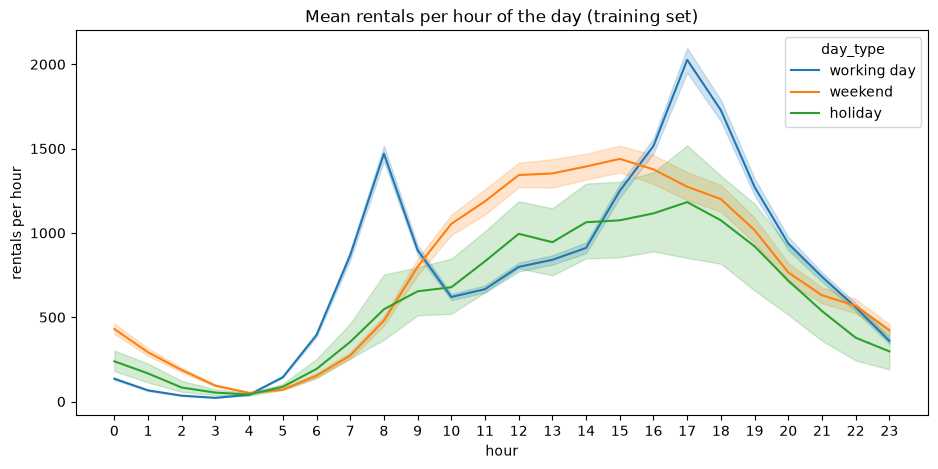

In [10]:
eda = df_train.copy()
eda["hour"] = eda["datetime"].dt.hour
eda["weekday"] = eda["datetime"].dt.dayofweek   # 0 = Monday, 6 = Sunday

# three types of day: a holiday counts as a holiday even if it falls on a weekday
eda["day_type"] = np.where(eda["holiday"].notna(), "holiday",
                  np.where(eda["weekday"] >= 5, "weekend", "working day"))

print(eda["day_type"].value_counts())

fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=eda, x="hour", y="rentals", hue="day_type",
             hue_order=["working day", "weekend", "holiday"], ax=ax)
ax.set_title("Mean rentals per hour of the day (training set)")
ax.set_xticks(range(0, 24))
ax.set_ylabel("rentals per hour")
plt.show()

**Finding:** the type of day changes the **shape** of the day, not just its level.
- **Working days** have two sharp peaks: the morning commute at **8:00** (≈ 1,450 rentals) and the evening commute at **17:00–18:00** (≈ 2,000, the busiest hours of all), with a dip around 10:00.
- **Weekends** have no commuting peaks; rentals rise slowly to one broad hump in the afternoon (≈ 1,400 around 12:00–16:00). Late at night (0:00–2:00), weekends are busier than working days: people go out on Friday and Saturday night.
- **Holidays** look like weekends, at a somewhat lower level, and with a wide confidence band, because there are only 466 holiday hours (≈ 20 days). So a holiday flag is needed, and a model has to learn **a different daily curve per type of day**.

### 2c. Weather and rentals

The weather is compared in **daytime hours only (7:00–20:00)**: at night rentals are low whatever the weather, so night hours would distort the comparison (confounding by the hour of the day).

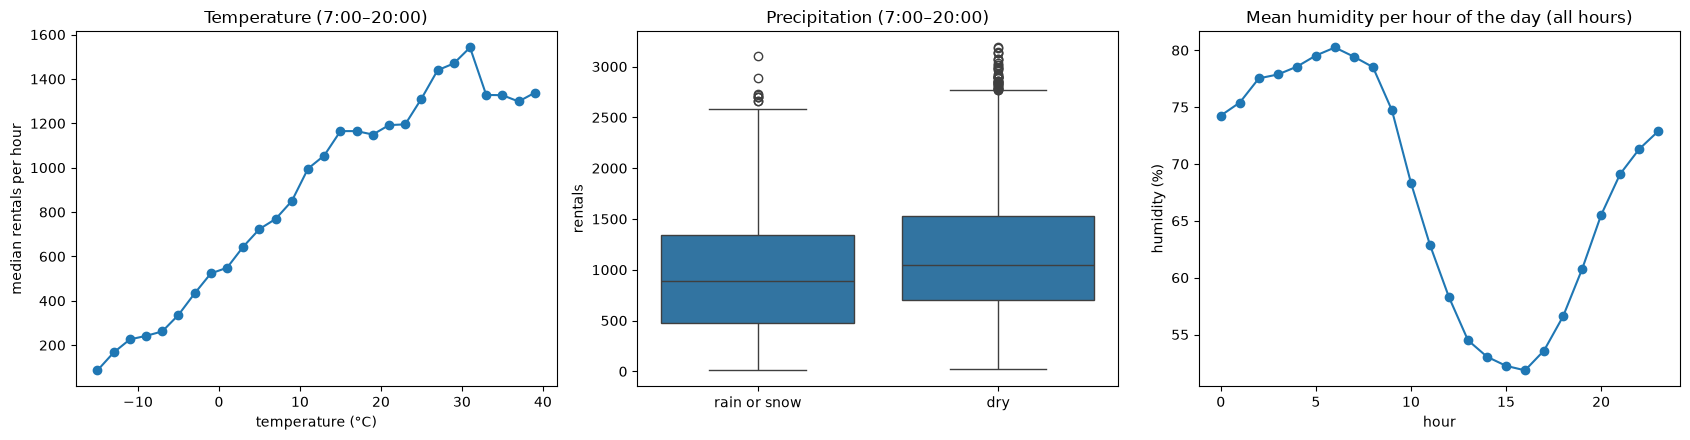

              count  median
wet                        
dry            6872  1048.0
rain or snow   1329   887.0


In [11]:
day = eda[eda["hour"].between(7, 20)].copy()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# temperature in 2-degree bins
day["temp_bin"] = pd.cut(day["temperature"], bins=range(-16, 42, 2))
temp = day.groupby("temp_bin", observed=True)["rentals"].median()
axes[0].plot([b.mid for b in temp.index], temp.values, marker="o")
axes[0].set_title("Temperature (7:00–20:00)")
axes[0].set_xlabel("temperature (°C)")
axes[0].set_ylabel("median rentals per hour")

# dry hours vs. hours with rain or snow
day["wet"] = np.where(day["precipitation"] > 0, "rain or snow", "dry")
sns.boxplot(data=day, x="wet", y="rentals", ax=axes[1])
axes[1].set_title("Precipitation (7:00–20:00)")
axes[1].set_xlabel("")

# humidity over the day: is it higher at night?
eda.groupby("hour")["humidity"].mean().plot(ax=axes[2], marker="o")
axes[2].set_title("Mean humidity per hour of the day (all hours)")
axes[2].set_ylabel("humidity (%)")

plt.tight_layout()
plt.show()

print(day.groupby("wet")["rentals"].agg(["count", "median"]))

**Findings:**
- **Temperature** is the strongest weather effect: median rentals rise steadily from ≈ 100 per hour at −15 °C to ≈ 1,500 at 30 °C, then drop again above ≈ 31 °C (too hot). That curve is not a straight line, which is why the correlation (≈ 0.48) understates it.
- **Rain or snow** lowers rentals (median 887 vs. 1,048 in dry daytime hours), although their correlation with rentals was close to 0: most hours are dry, and the effect is a jump between dry and wet, not a straight line.
- **Humidity** is highest at night and in the early morning (≈ 80 %) and lowest in the afternoon (≈ 52 %). Its negative correlation with rentals (−0.43) is mostly **the hour of the day in disguise**, not people avoiding humid air. It stays a feature, but the correlation should not be read as its effect.

**Is `weather_code` new information?** For each code, the ranges of the other weather columns:

In [12]:
df_train.groupby("weather_code")[["precipitation", "snowfall", "cloud_cover"]].agg(["min", "max"])

precipitation       snowfall       cloud_cover     
                       min   max      min   max         min  max
weather_code                                                    
0                      0.0   0.0     0.00  0.00           0   19
1                      0.0   0.0     0.00  0.00          20   49
2                      0.0   0.0     0.00  0.00          50   79
3                      0.0   0.0     0.00  0.00          80  100
51                     0.1   0.4     0.00  0.00           2  100
53                     0.5   0.9     0.00  0.00           3  100
55                     1.0   1.2     0.00  0.00           8  100
61                     1.3   2.4     0.00  0.00          32  100
63                     2.5   7.5     0.00  0.00          28  100
65                     7.7  13.6     0.00  0.00          84  100
71                     0.1   3.5     0.07  0.14          25  100
73                     0.3   2.8     0.21  0.77          99  100
75                     1.3   2.9     0.91  2.03         100  100

**Finding:** the ranges do not overlap. Codes 0–3 have no rain or snow and differ only by `cloud_cover` (0–19, 20–49, 50–79, 80–100 %). Drizzle and rain (51–65) are separated by the amount of `precipitation`, and snow (71–75) is every hour with `snowfall` above 0. So `weather_code` is a **binned version of `precipitation`, `snowfall` and `cloud_cover`**. Trees can learn the same thresholds from those columns directly, so `weather_code` is dropped.

### 2d. Redundant columns and leakage

Correlations between the numeric columns (lower triangle only, because the matrix is symmetric):

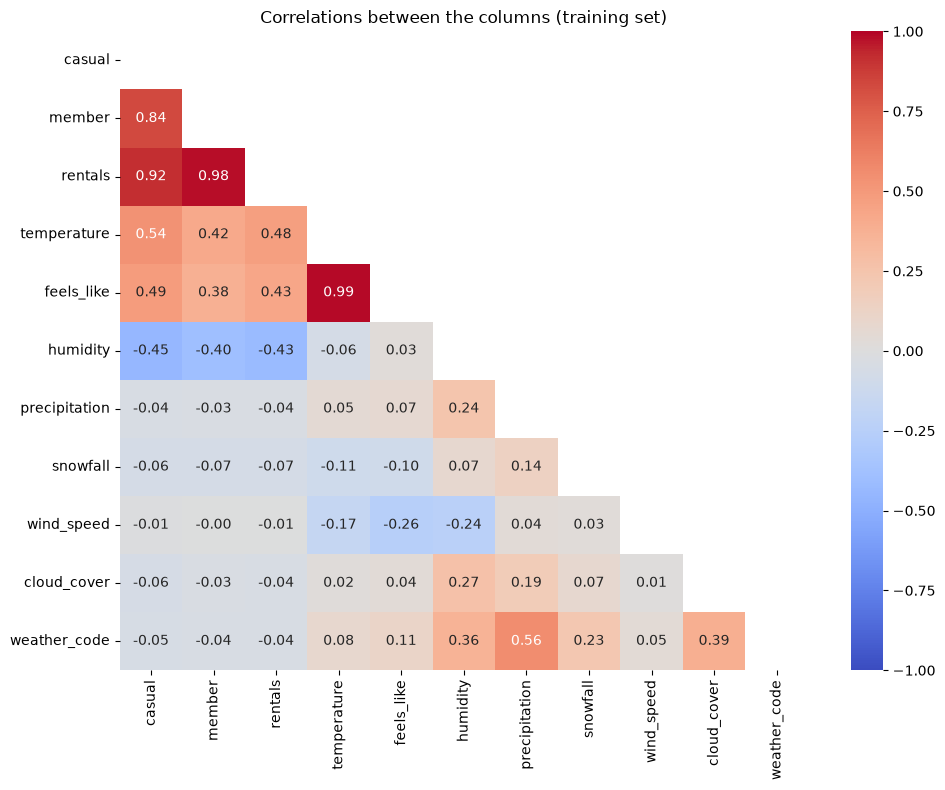

In [13]:
numeric = df_train.select_dtypes("number")
corr = numeric.corr()

# True for the upper triangle and the diagonal -> those cells get hidden
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlations between the columns (training set)")
plt.tight_layout()
plt.show()

- `temperature` and `feels_like` correlate at **0.99**: they are practically the same column. For `Ridge` that makes the coefficients unstable (collinearity), for trees it is only redundant. **Keep `temperature`** (stronger link to rentals, easier to explain), **drop `feels_like`**.
- `casual` and `member` correlate very strongly with `rentals`. That is suspicious, so check the leakage question: *would I know the value for an hour without having counted that hour's rentals?*

In [14]:
# do the two rider groups add up to the target?
same = df_train["casual"] + df_train["member"] == df_train["rentals"]
print(f"casual + member == rentals in {same.mean():.1%} of the hours")

casual + member == rentals in 100.0% of the hours


**Leakage:** `casual + member == rentals` in every hour. They are not features but **the target split into two parts**: you only know them after counting that hour's rentals. A model given them would just add them up and look perfect, but it could never be used for planning. **Drop `casual` and `member`.**

All other columns pass the check: the time comes from the calendar, and the weather can be known (or forecast) without counting rentals.

**Is there a difference between the two years?** The test hours are drawn from both years, so the year is a legitimate feature, if the level differs:

In [15]:
eda["year"] = eda["datetime"].dt.year
eda["month"] = eda["datetime"].dt.month
eda.groupby(["month", "year"])["rentals"].mean().round().unstack()

year,2024,2025,2026
month,,,
1,NaN,392.0,354.0
2,NaN,543.0,361.0
3,NaN,821.0,679.0
4,NaN,935.0,832.0
5,NaN,916.0,805.0
6,NaN,978.0,919.0
7,NaN,938.0,888.0
8,NaN,847.0,882.0
9,NaN,870.0,943.0


**Finding:** the season matters a lot (fewest rentals in January and February, most from April to October), and the same month can differ between years by 10–30 % (e.g. February 2025: 543 vs. February 2026: 361, probably a colder or snowier month). So `month` is a feature, and `year` is added too, so that the model can tell the two years apart.

### Record of manual changes and `prepare()`

Every change to the data by hand, collected in one function, so that exactly the same changes can be applied to the test set in step 8:

1. Drop the two hours that do not exist because of daylight saving time (second Sunday of March, 02:00).
2. New columns from `datetime`: `hour`, `weekday` (0 = Monday), `month`, `year`.
3. `is_holiday` = 1 if `holiday` is not NaN, else 0.
4. `is_working_day` = 1 for Monday–Friday that is not a holiday, else 0.
5. Drop `holiday` (replaced by the flag), `feels_like` (r = 0.99 with `temperature`), `weather_code` (derived from the other weather columns), and `casual` and `member` (**leakage**).

`datetime` stays in the DataFrame so that the date of each hour can be shown in the test step ; it is only left out of `X`.

Scaling and one-hot encoding are **not** done here: they learn values from the data, so they go into the `Pipeline`, which learns them from the training folds only.